In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Columns:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

First 5 rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Number of samples:
100

Class distribution:
target
0    50
1    50
Name: count, dtype: int64

SVM RESULTS
Accuracy: 100.00%

Confusion Matrix:
[[13  0]
 [ 0 12]]


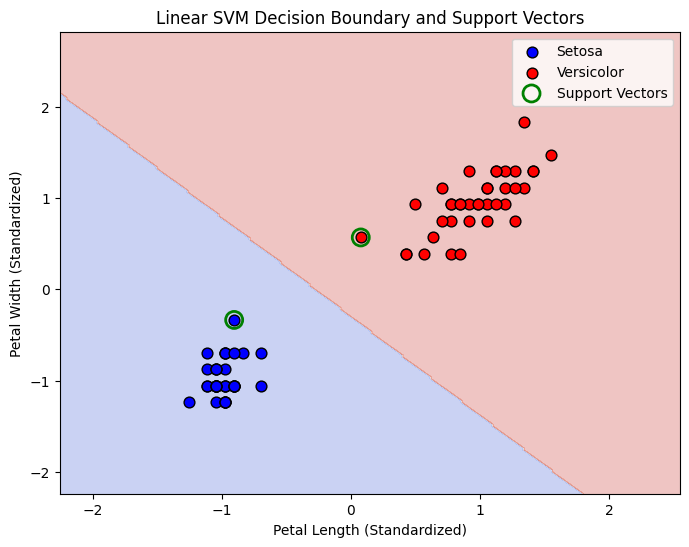

In [24]:
# ==========================================================
# SVM - Iris Binary Classification
# Setosa vs Versicolor
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix


# ----------------------------------------------------------
# 1. Load Dataset
# ----------------------------------------------------------

df = pd.read_csv("/content/drive/MyDrive/ML_LAB/iris.csv")

print("Columns:")
print(df.columns)

print("\nFirst 5 rows:")
print(df.head())


# ----------------------------------------------------------
# 2. Binary Classification
# ----------------------------------------------------------

# Keep only Setosa and Versicolor
df = df[df['species'].isin(['setosa', 'versicolor'])].copy()


# Convert classes to numbers
# setosa = 0
# versicolor = 1

df['target'] = df['species'].map({
    'setosa': 0,
    'versicolor': 1
})


# ----------------------------------------------------------
# 3. Select Two Features
# ----------------------------------------------------------

X = df[['petal_length', 'petal_width']]
y = df['target']


print("\nNumber of samples:")
print(len(df))

print("\nClass distribution:")
print(y.value_counts())


# ----------------------------------------------------------
# 4. Train-Test Split
# ----------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


# ----------------------------------------------------------
# 5. Feature Scaling
# ----------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ----------------------------------------------------------
# 6. Train Linear SVM
# ----------------------------------------------------------

linear_svm = SVC(
    kernel='linear',
    C=1.0,
    random_state=42
)

linear_svm.fit(X_train_scaled, y_train)


# ----------------------------------------------------------
# 7. Prediction
# ----------------------------------------------------------

y_pred = linear_svm.predict(X_test_scaled)


# ----------------------------------------------------------
# 8. Accuracy
# ----------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\n==============================")
print("SVM RESULTS")
print("==============================")

print(f"Accuracy: {accuracy * 100:.2f}%")


# ----------------------------------------------------------
# 9. Confusion Matrix
# ----------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# ----------------------------------------------------------
# 10. Create Grid for Decision Boundary
# ----------------------------------------------------------

x_min = X_train_scaled[:, 0].min() - 1
x_max = X_train_scaled[:, 0].max() + 1

y_min = X_train_scaled[:, 1].min() - 1
y_max = X_train_scaled[:, 1].max() + 1


xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)


# ----------------------------------------------------------
# 11. Predict Grid Points
# ----------------------------------------------------------

grid = np.c_[xx.ravel(), yy.ravel()]

Z = linear_svm.predict(grid)

# Reshape for contour plot
Z = Z.reshape(xx.shape)


# ----------------------------------------------------------
# 12. Plot Decision Boundary
# ----------------------------------------------------------

plt.figure(figsize=(8, 6))


# Decision regions
plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap=plt.cm.coolwarm
)


# Training data - Setosa
plt.scatter(
    X_train_scaled[y_train == 0, 0],
    X_train_scaled[y_train == 0, 1],
    color='blue',
    edgecolors='black',
    s=60,
    label='Setosa'
)


# Training data - Versicolor
plt.scatter(
    X_train_scaled[y_train == 1, 0],
    X_train_scaled[y_train == 1, 1],
    color='red',
    edgecolors='black',
    s=60,
    label='Versicolor'
)


# ----------------------------------------------------------
# 13. Highlight Support Vectors
# ----------------------------------------------------------

plt.scatter(
    linear_svm.support_vectors_[:, 0],
    linear_svm.support_vectors_[:, 1],
    s=150,
    facecolors='none',
    edgecolors='green',
    linewidths=2,
    label='Support Vectors'
)


# ----------------------------------------------------------
# 14. Labels and Title
# ----------------------------------------------------------

plt.xlabel("Petal Length (Standardized)")
plt.ylabel("Petal Width (Standardized)")

plt.title(
    "Linear SVM Decision Boundary and Support Vectors"
)

plt.legend()

plt.show()
